In [7]:
# RNN Project - Next Day Sales Prediction
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from keras import Sequential
from keras.layers import Input,SimpleRNN,Dense


In [8]:
sales_data = {
    "Monday":100,
    "Tuesday":120,
    "Wednesday":110,
    "Thursday":140,
    "Friday":160,
    "Saturday":180,
    "Sunday":170,

    "Monday_2":190,
    "Tuesday_2":210,
    "Wednesday_2":200,
    "Thursday_2":230,
    "Friday_2":250,
    "Saturday_2":270,
    "Sunday_2":260,

    "Monday_3":270,
    "Tuesday_3":260,
    "Wednesday_3":290,
    "Thursday_3":310,
    "Friday_3":330,
    "Saturday_3":350,
    "Sunday_3":370,
}

In [9]:
df = pd.DataFrame({
    "Day":list(sales_data.keys()),
    "Sales":list(sales_data.values())
})

In [11]:
print("DAY WISE SALES DATA")
print(df.to_string(index=False))

DAY WISE SALES DATA
        Day  Sales
     Monday    100
    Tuesday    120
  Wednesday    110
   Thursday    140
     Friday    160
   Saturday    180
     Sunday    170
   Monday_2    190
  Tuesday_2    210
Wednesday_2    200
 Thursday_2    230
   Friday_2    250
 Saturday_2    270
   Sunday_2    260
   Monday_3    270
  Tuesday_3    260
Wednesday_3    290
 Thursday_3    310
   Friday_3    330
 Saturday_3    350
   Sunday_3    370


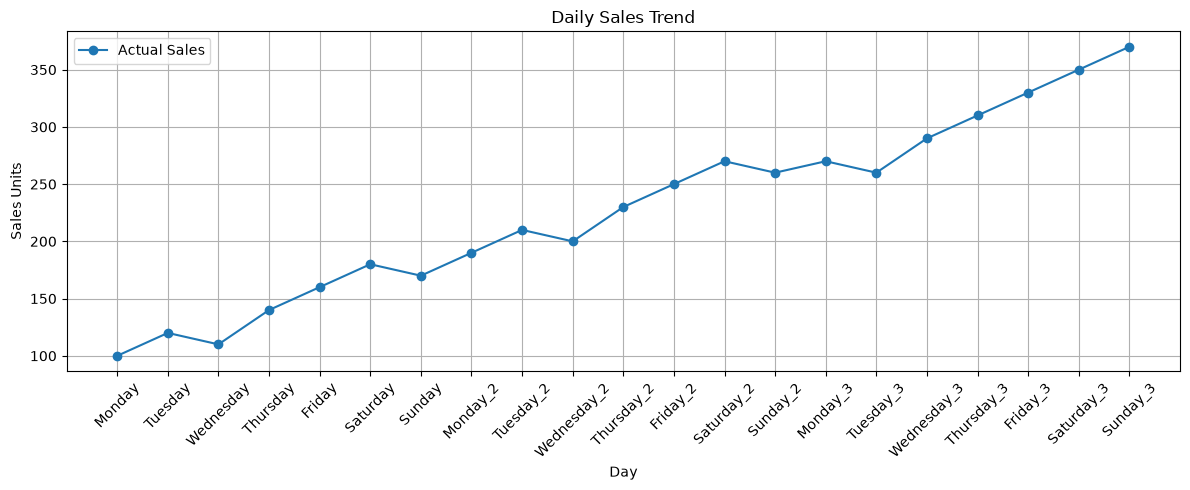

In [17]:
#data visualization
plt.figure(figsize=(12,5))
plt.plot(
    range(len(df)),
    df["Sales"],
    marker="o",
    label="Actual Sales"
)

# X axis usme label dikhane h
plt.xticks(
    range(len(df)),
    df["Day"],
    rotation=45
)

plt.title("Daily Sales Trend")
plt.xlabel("Day")
plt.ylabel("Sales Units")

plt.grid(True)
plt.legend()

# data labels vo overlap
plt.tight_layout()
plt.show()

In [21]:
# Sales value ko numpy array
sales = df["Sales"].to_numpy(dtype=np.float32)

# original sales value ko maximum scale
max_sales = float(sales.max())

# sales ko 0 to 1 me
scaled_sales = sales/max_sales


In [22]:
scaled_sales

array([0.27027026, 0.3243243 , 0.2972973 , 0.3783784 , 0.43243244,
       0.4864865 , 0.45945945, 0.5135135 , 0.5675676 , 0.5405405 ,
       0.6216216 , 0.6756757 , 0.7297297 , 0.7027027 , 0.7297297 ,
       0.7027027 , 0.7837838 , 0.8378378 , 0.8918919 , 0.9459459 ,
       1.        ], dtype=float32)

In [24]:
#input ki sequence
# pichle 3 days ki sales k hisab se agle din ki sales btani h
window_size=3
x=[]
#input seq
y=[]
# correct next day output sales

# har possible 3 days window ko input bnaye
# monday,tue,wed
for i in range(len(scaled_sales)-window_size):
    x.append(scaled_sales[i:i+window_size])

# Thursday ki sales target
    y.append(scaled_sales[i+window_size])


In [25]:
# list ko numpy array me convert krdenge
x = np.array(x,dtype=np.float32)
y = np.array(y,dtype=np.float32)

In [ ]:
# RNN input shape (Samples,steps,features)
